# Convert an HDF5 4D-STEM dataset to the 198.zip (Zarr) format

This notebook takes a 4D-STEM diffraction dataset stored in an **HDF5** file and writes it in the same
zipped **Zarr** layout as `198.zip` (the TEAM 0.5 / 4D Camera ptychographic tomography data):

| Entry | Contents |
|---|---|
| `.zgroup` | Zarr group header |
| `data/` | 16-bit integer counts, shape `(scan_y, scan_x, det_y, det_x)`, chunks `(66, 66, det_y, det_x)` (smaller automatically for large detectors), Blosc lz4 compression |
| `meta/` | one JSON record: `E_ev`, `aberrations` (12), `alpha_rad`, `k_max`, `pixel_step`, `rotation_deg`, `sample_thickness_guess_angstrom`, `scan_step`, `wavelength` |

**How to use it:** work through the steps in order. You only need to edit the cells marked ✏️.

1. Point the notebook at your file and look at what's inside.
2. Fill in the microscope settings.
3. Check the detector calibration on a plot *before* converting.
4. Convert.
5. Verify the new file.

Requirements: `pip install h5py hdf5plugin numpy matplotlib "zarr<3" numcodecs`

`hdf5plugin` adds the compression filters (bitshuffle/LZ4, Blosc, Zstd, LZ4, …) that detector data are
often stored with. Without it, reading compressed data fails with
`OSError: Can't synchronously read data (can't open directory (/usr/local/lib/plugin) ...)`.

In [1]:
import json
import numpy as np
import h5py
try:
    import hdf5plugin  # registers extra HDF5 compression filters; must be imported before reading data
    print("hdf5plugin", hdf5plugin.version, "loaded")
except ImportError:
    print("WARNING: hdf5plugin is not installed. If your data are compressed, run\n"
          "    pip install hdf5plugin\nthen restart the kernel and run the notebook again.")
import zarr
import numcodecs
from numcodecs import Blosc
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

print("zarr", zarr.__version__, "| numcodecs", numcodecs.__version__, "| h5py", h5py.__version__)
assert int(zarr.__version__.split(".")[0]) == 2, "This notebook needs zarr version 2:  pip install 'zarr<3'"

hdf5plugin 4.1.3 loaded
zarr 2.18.3 | numcodecs 0.12.1 | h5py 3.16.0


## Step 1 — Point at your file ✏️

In [2]:
INPUT_H5 = "/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_125551/20260524_125551_data.hdf5"      # your HDF5 file
OUTPUT_ZIP = "/dls/science/groups/e02/Joshua/Python_code/End_to_End/test.zip"   # the converted file to write

Run the next cell to list everything in the HDF5 file: groups, datasets (with shape and type) and any
attributes. Look for the 4D diffraction dataset, and for attributes that hold the microscope settings
you'll need in Step 2 (voltage, convergence angle, scan step, camera length or detector calibration).

In [3]:
def filter_names(dset):
    # Names of the HDF5 filters (compression etc.) applied to a dataset
    plist = dset.id.get_create_plist()
    names = []
    for i in range(plist.get_nfilters()):
        code, _, _, name = plist.get_filter(i)
        name = name.decode(errors="replace") if isinstance(name, bytes) else str(name)
        names.append(f"{name} (id {code})")
    return names


def list_h5(path):
    def show(name, obj):
        if isinstance(obj, h5py.Dataset):
            filt = ", ".join(filter_names(obj)) or "none"
            print(f"[dataset] /{name}   shape={obj.shape}   dtype={obj.dtype}   compression: {filt}")
        else:
            print(f"[group]   /{name}")
        for k, v in obj.attrs.items():
            s = repr(v)
            print(f"             @{k} = {s[:120]}{'...' if len(s) > 120 else ''}")

    with h5py.File(path, "r") as f:
        for k, v in f.attrs.items():
            print(f"[file attribute] @{k} = {repr(v)[:120]}")
        f.visititems(show)

list_h5(INPUT_H5)

[file attribute] @file_format = 'HyperSpy'
[file attribute] @file_format_version = '3.3'
[group]   /Experiments
[group]   /Experiments/__unnamed__
             @package = 'hyperspy'
             @package_version = '2.2.0'
[group]   /Experiments/__unnamed__/attributes
             @_lazy = np.False_
             @ragged = np.False_
[group]   /Experiments/__unnamed__/axis-0
             @_type = 'UniformDataAxis'
             @is_binned = np.False_
             @name = '_None_'
             @navigate = np.True_
             @offset = np.float64(0.0)
             @scale = np.float64(1.0)
             @size = np.int64(255)
             @units = '_None_'
[group]   /Experiments/__unnamed__/axis-1
             @_type = 'UniformDataAxis'
             @is_binned = np.False_
             @name = '_None_'
             @navigate = np.True_
             @offset = np.float64(0.0)
             @scale = np.float64(1.0)
             @size = np.int64(255)
             @units = '_None_'
[group]   /Experi

## Step 2 — Microscope settings ✏️

The values filled in below are the ones stored in `198.zip`. Replace them with the settings for your data.

* **`DATASET`** – path of the diffraction data inside the HDF5 file (from the listing above).
  Leave as `None` to pick it automatically when there is exactly one 4D dataset.
* **`SCAN_SHAPE`** – only needed if the patterns are stored as a flat stack `(n_patterns, det_y, det_x)`;
  then give the scan grid, e.g. `(220, 220)`. The data are assumed to be ordered
  `(scan_y, scan_x, det_y, det_x)`.
* **Detector calibration** – fill in **exactly one** of `K_MAX`, `DK` or `MRAD_PER_PX` and leave the
  other two as `None`.
* **`DEFOCUS_A`** – probe defocus in Å, stored as the first aberration coefficient (198.zip uses −252).
  Use `ABERRATIONS` instead if you have all 12 coefficients.
* **`BIN`** – optional detector binning. `1` keeps every pixel; `2`, `4`, `8`… add up `BIN × BIN` blocks of
  pixels, making the patterns (and the file) smaller. Give the detector calibration for the *unbinned*
  detector; the notebook adjusts it. 198.zip has 66 × 66-pixel patterns at 0.038 Å⁻¹ per pixel.
* **`CHUNK`** – leave as `None`. It then uses 66 × 66 scan positions per block like 198.zip, or fewer
  when the patterns are large (the compressor can't handle blocks over 2 GB).

In [4]:
DATASET = None            # e.g. "/entry/data"; None = find the 4D dataset automatically
SCAN_SHAPE = None         # e.g. (220, 220), only for a flat (n_patterns, det_y, det_x) stack

VOLTAGE_KV = 300.0         # accelerating voltage, kV
ALPHA_MRAD = 26.7         # probe convergence semi-angle, mrad
SCAN_STEP_A = (0.40250373, 0.40250373)   # scan step (y, x), Å

# Detector calibration: fill in exactly ONE of these three, leave the others as None
K_MAX = 1.2602931552587406   # half-width of the detector, 1/Å (as stored in meta.k_max)
DK = None                     # size of one detector pixel, 1/Å
MRAD_PER_PX = None            # size of one detector pixel, mrad

DEFOCUS_A = -252.0        # defocus C1, Å
ABERRATIONS = None        # or a list of all 12 coefficients (overrides DEFOCUS_A)
ROTATION_DEG = 0.0        # scan-to-detector rotation, degrees
THICKNESS_A = 0.0         # sample thickness guess, Å

BIN = 1                   # detector binning: 1 = none; 2, 4, 8 ... = sum BIN x BIN pixels
CHUNK = None              # scan positions per block; None = automatic (66 like 198.zip, fewer for big patterns)

The next cell works out everything else from these settings (wavelength, detector calibration, the
metadata record) and shows it. Nothing is written yet.

In [5]:
def electron_wavelength_angstrom(voltage_v):
    # Relativistic electron wavelength in Å
    h, m0, e, c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0
    p = np.sqrt(2 * m0 * e * voltage_v * (1 + e * voltage_v / (2 * m0 * c**2)))
    return h / p * 1e10


def as_pair(v):
    return [float(v), float(v)] if np.isscalar(v) else [float(x) for x in v]


def find_dataset(f):
    if DATASET:
        return f[DATASET]
    found = []
    f.visititems(lambda n, o: found.append(o.name) if isinstance(o, h5py.Dataset)
                 and (o.ndim == 4 or (o.ndim == 3 and SCAN_SHAPE)) else None)
    if len(found) != 1:
        raise ValueError(f"Found {len(found)} candidate datasets {found}; set DATASET in Step 2.")
    return f[found[0]]


with h5py.File(INPUT_H5, "r") as f:
    src = find_dataset(f)
    DATASET_PATH, SRC_SHAPE, SRC_DTYPE = src.name, src.shape, src.dtype
    SRC_FILTERS = filter_names(src)
    # test-read one pattern so a missing decompression filter shows up here, with a clear message
    try:
        src[(0,) * (src.ndim - 2)]
    except OSError as err:
        raise RuntimeError(
            f"Can't decompress {DATASET_PATH} (filters: {', '.join(SRC_FILTERS) or 'none'}).\n"
            "Install the extra HDF5 filters with   pip install hdf5plugin   then restart the kernel\n"
            "and run the notebook from the top (the import cell loads hdf5plugin).\n"
            f"Original error: {err}") from None

if len(SRC_SHAPE) == 4:
    Ry, Rx, Qy_raw, Qx_raw = SRC_SHAPE
elif len(SRC_SHAPE) == 3 and SCAN_SHAPE:
    Ry, Rx = SCAN_SHAPE
    Qy_raw, Qx_raw = SRC_SHAPE[1:]
    assert SRC_SHAPE[0] == Ry * Rx, f"SCAN_SHAPE gives {Ry*Rx} patterns but the dataset has {SRC_SHAPE[0]}"
else:
    raise ValueError(f"Dataset shape {SRC_SHAPE}: expected 4D, or 3D with SCAN_SHAPE set.")

assert sum(x is not None for x in (K_MAX, DK, MRAD_PER_PX)) == 1, \
    "Set exactly one of K_MAX, DK, MRAD_PER_PX"
assert isinstance(BIN, int) and BIN >= 1, "BIN must be a whole number >= 1"

lam = electron_wavelength_angstrom(VOLTAGE_KV * 1e3)
# calibration of the raw (unbinned) detector pixels
if K_MAX is not None:
    k_raw = as_pair(K_MAX)
    dk_raw = [2 * k_raw[0] / Qy_raw, 2 * k_raw[1] / Qx_raw]
else:
    dk_raw = as_pair(DK) if DK is not None else [m * 1e-3 / lam for m in as_pair(MRAD_PER_PX)]

# optional binning: leftover edge pixels (if the size isn't a multiple of BIN) are cropped evenly
Qy, Qx = Qy_raw // BIN, Qx_raw // BIN
crop_y, crop_x = (Qy_raw - Qy * BIN) // 2, (Qx_raw - Qx * BIN) // 2
dk = [d * BIN for d in dk_raw]
k_max = [Qy * dk[0] / 2, Qx * dk[1] / 2]

# block (chunk) size: the Blosc compressor can't take blocks over 2 GB, so keep them under 1 GB
bytes_per_pattern = Qy * Qx * 2
if CHUNK is None:
    CHUNK_USED = 66 if 66 * 66 * bytes_per_pattern <= 2**30 else max(1, int(np.sqrt(2**30 / bytes_per_pattern)))
else:
    CHUNK_USED = int(CHUNK)
assert CHUNK_USED**2 * bytes_per_pattern < 2**31, \
    f"CHUNK={CHUNK_USED} makes blocks over 2 GB; set CHUNK = None"

aberrations = [float(a) for a in ABERRATIONS] if ABERRATIONS is not None else [float(DEFOCUS_A)] + [0.0] * 11
assert len(aberrations) == 12, "ABERRATIONS needs 12 values"

meta = {
    "E_ev": VOLTAGE_KV * 1e3,
    "aberrations": aberrations,
    "alpha_rad": ALPHA_MRAD * 1e-3,
    "k_max": k_max,
    "pixel_step": [1.0, 1.0],
    "rotation_deg": float(ROTATION_DEG),
    "sample_thickness_guess_angstrom": float(THICKNESS_A),
    "scan_step": as_pair(SCAN_STEP_A),
    "wavelength": float(lam),
}

expected_radius_px = ALPHA_MRAD * 1e-3 / lam / np.sqrt(dk[0] * dk[1])
print(f"Dataset {DATASET_PATH}: shape {SRC_SHAPE}, dtype {SRC_DTYPE}, "
      f"compression: {', '.join(SRC_FILTERS) or 'none'}")
if BIN > 1:
    print(f"Binning {BIN}x{BIN}: detector {Qy_raw}x{Qx_raw} -> {Qy}x{Qx} pixels"
          + (f" (cropping {Qy_raw - Qy*BIN}/{Qx_raw - Qx*BIN} edge pixels)" if (Qy_raw % BIN or Qx_raw % BIN) else ""))
print(f"Output shape (scan_y, scan_x, det_y, det_x) = {(Ry, Rx, Qy, Qx)}")
print(f"Blocks of {CHUNK_USED}x{CHUNK_USED} scan positions = {CHUNK_USED**2 * bytes_per_pattern / 1e9:.2f} GB each "
      f"(uncompressed); whole dataset {Ry * Rx * bytes_per_pattern / 1e9:.1f} GB uncompressed")
print(f"Field of view: {Ry * meta['scan_step'][0] / 10:.2f} x {Rx * meta['scan_step'][1] / 10:.2f} nm")
print(f"Detector: {dk[0]:.4f} 1/Å per pixel = {dk[0] * lam * 1e3:.3f} mrad per pixel")
print(f"Expected bright-field disk radius: {expected_radius_px:.1f} pixels\n")
print("Metadata record to be written:")
print(json.dumps(meta, indent=2))

Dataset /Experiments/__unnamed__/data: shape (255, 255, 515, 515), dtype uint8, compression: blosc (id 32001)
Output shape (scan_y, scan_x, det_y, det_x) = (255, 255, 515, 515)
Blocks of 44x44 scan positions = 1.03 GB each (uncompressed); whole dataset 34.5 GB uncompressed
Field of view: 10.26 x 10.26 nm
Detector: 0.0049 1/Å per pixel = 0.204 mrad per pixel
Expected bright-field disk radius: 122.3 pixels

Metadata record to be written:
{
  "E_ev": 80000.0,
  "aberrations": [
    -252.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0
  ],
  "alpha_rad": 0.025,
  "k_max": [
    1.2602931552587406,
    1.2602931552587406
  ],
  "pixel_step": [
    1.0,
    1.0
  ],
  "rotation_deg": 0.0,
  "sample_thickness_guess_angstrom": 0.0,
  "scan_step": [
    0.40250373,
    0.40250373
  ],
  "wavelength": 0.04175716077283421
}


## Step 3 — Check the calibration before converting

This averages a sample of the diffraction patterns and draws the bright-field disk your settings predict
(dashed circle) on top of it. **The dashed circle should sit on the edge of the bright disk.** If it is
clearly too big or too small, the convergence angle or the detector calibration in Step 2 is off.

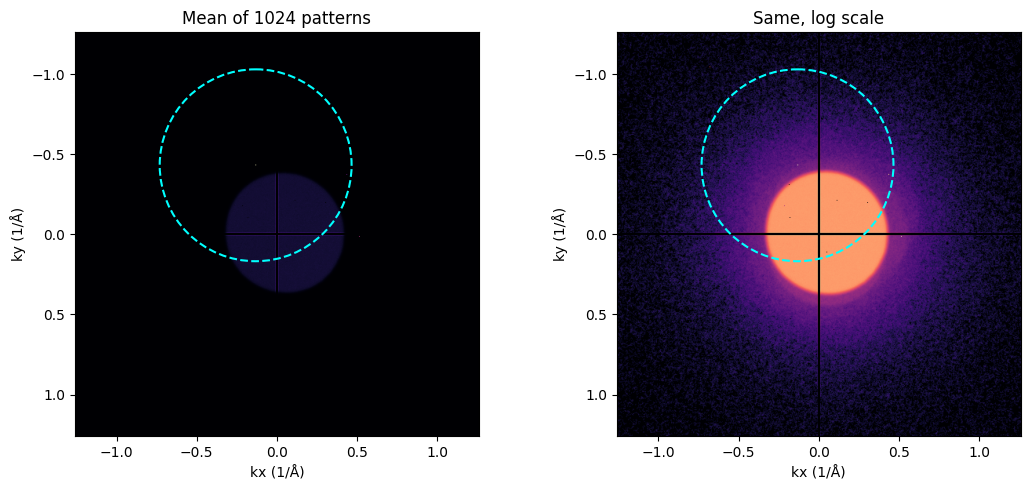

Bright-field disk: measured radius 0.6 px, expected 122.3 px
Disk centre at detector pixel (169.0, 230.0); detector centre is (257.0, 257.0)


In [6]:
def bin_patterns(a):
    # Crop leftover edge pixels and add up BIN x BIN blocks of detector pixels
    if BIN == 1:
        return a
    a = a[..., crop_y:crop_y + Qy * BIN, crop_x:crop_x + Qx * BIN]
    return a.reshape(a.shape[:-2] + (Qy, BIN, Qx, BIN)).sum(axis=(-3, -1))


def read_block(src, r0, r1, c0, c1):
    # Return (binned) patterns for scan rows r0:r1, columns c0:c1 as an array (r, c, det_y, det_x).
    # With binning, one scan row is read and binned at a time to keep memory use low.
    if src.ndim == 4:
        if BIN == 1:
            return np.asarray(src[r0:r1, c0:c1])
        return np.stack([bin_patterns(np.asarray(src[r, c0:c1])) for r in range(r0, r1)])
    return np.stack([bin_patterns(np.asarray(src[r * Rx + c0:r * Rx + c1])) for r in range(r0, r1)])


def disk_from_mean(mean_dp):
    mask = mean_dp > 0.5 * mean_dp.max()
    yy, xx = np.nonzero(mask)
    return yy.mean(), xx.mean(), np.sqrt(mask.sum() / np.pi)


# average a sparse grid of ~1000 patterns
step = max(1, int(np.sqrt(Ry * Rx / 1000)))
rows, cols = range(0, Ry, step), range(0, Rx, step)
acc, n = np.zeros((Qy, Qx)), 0
with h5py.File(INPUT_H5, "r") as f:
    src = f[DATASET_PATH]
    for r in rows:
        for c in cols:
            acc += read_block(src, r, r + 1, c, c + 1)[0, 0]
            n += 1
sample_mean = acc / n
cy, cx, r_meas = disk_from_mean(sample_mean)

ext = [-k_max[1], k_max[1], k_max[0], -k_max[0]]
to_k = lambda py, px: ((py - (Qy - 1) / 2) * dk[0], (px - (Qx - 1) / 2) * dk[1])
ky0, kx0 = to_k(cy, cx)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a, img, title in [(ax[0], sample_mean, "Mean of %d patterns" % n),
                      (ax[1], np.log10(sample_mean + 1e-3), "Same, log scale")]:
    a.imshow(img, extent=ext, cmap="magma")
    a.add_patch(Circle((kx0, ky0), expected_radius_px * np.sqrt(dk[0] * dk[1]),
                       fill=False, ls="--", lw=1.5, color="cyan"))
    a.set_title(title); a.set_xlabel("kx (1/Å)"); a.set_ylabel("ky (1/Å)")
plt.tight_layout(); plt.show()

print(f"Bright-field disk: measured radius {r_meas:.1f} px, expected {expected_radius_px:.1f} px")
print(f"Disk centre at detector pixel ({cy:.1f}, {cx:.1f}); detector centre is "
      f"({(Qy - 1) / 2:.1f}, {(Qx - 1) / 2:.1f})")
if abs(r_meas - expected_radius_px) > 0.1 * expected_radius_px:
    print("WARNING: these differ by more than 10% - check ALPHA_MRAD and the detector calibration.")
else:
    print("OK: calibration and convergence angle are consistent.")

## Step 4 — Convert

Writes `OUTPUT_ZIP` block by block (the block size was chosen in Step 2), so even large datasets don't
need to fit in memory. Counts are stored
as 16-bit integers: decimal values are rounded (with a note), and values outside −32768…32767 stop the
conversion, because that usually means the data are scaled rather than raw electron counts.

While it runs, it also builds a virtual bright-field image (counts inside the bright disk at each scan
position) for the check in Step 5.

In [7]:
yy, xx = np.mgrid[:Qy, :Qx]
bf_mask = np.hypot(yy - cy, xx - cx) <= 0.9 * r_meas

store = zarr.ZipStore(OUTPUT_ZIP, mode="w")
try:
    root = zarr.group(store=store, overwrite=True)
    out = root.create_dataset(
        "data", shape=(Ry, Rx, Qy, Qx), chunks=(min(CHUNK_USED, Ry), min(CHUNK_USED, Rx), Qy, Qx),
        dtype="<i2", fill_value=0, order="C",
        compressor=Blosc(cname="lz4", clevel=1, shuffle=Blosc.SHUFFLE))

    n_rounded, vmin, vmax = 0, np.inf, -np.inf
    total = np.zeros((Ry, Rx))
    vbf = np.zeros((Ry, Rx))
    mean_dp = np.zeros((Qy, Qx))
    with h5py.File(INPUT_H5, "r") as f:
        src = f[DATASET_PATH]
        for r0 in range(0, Ry, CHUNK_USED):
            r1 = min(r0 + CHUNK_USED, Ry)
            for c0 in range(0, Rx, CHUNK_USED):
                c1 = min(c0 + CHUNK_USED, Rx)
                blk = read_block(src, r0, r1, c0, c1)
                if not np.issubdtype(blk.dtype, np.integer):
                    rounded = np.rint(blk)
                    n_rounded += int(np.count_nonzero(np.abs(blk - rounded) > 1e-6))
                    blk = rounded
                if blk.min() < -32768 or blk.max() > 32767:
                    raise ValueError(f"Values {blk.min()}..{blk.max()} don't fit in int16; "
                                     "rescale the data to electron counts first.")
                vmin, vmax = min(vmin, blk.min()), max(vmax, blk.max())
                blk = blk.astype("<i2")
                out[r0:r1, c0:c1] = blk
                total[r0:r1, c0:c1] = blk.sum(axis=(2, 3))
                vbf[r0:r1, c0:c1] = blk[..., bf_mask].sum(axis=-1)
                mean_dp += blk.sum(axis=(0, 1))
                del blk
            print(f"wrote scan rows {r0}-{r1 - 1} of {Ry}")

    m = root.create_dataset("meta", shape=(1,), chunks=(1,), dtype=object,
                            object_codec=numcodecs.JSON(),
                            compressor=Blosc(cname="lz4", clevel=5, shuffle=Blosc.SHUFFLE))
    m[0] = meta
finally:
    store.close()

mean_dp /= Ry * Rx
print(f"\nWrote {OUTPUT_ZIP}")
print(f"Values {vmin}..{vmax}; mean counts per pattern {total.mean():.1f}")
if n_rounded:
    print(f"NOTE: {n_rounded} non-integer values were rounded to whole numbers.")

wrote scan rows 0-43 of 255
wrote scan rows 44-87 of 255
wrote scan rows 88-131 of 255
wrote scan rows 132-175 of 255
wrote scan rows 176-219 of 255
wrote scan rows 220-254 of 255

Wrote /dls/science/groups/e02/Joshua/Python_code/End_to_End/test.zip
Values 0..63; mean counts per pattern 109790.0


## Step 5 — Verify the new file

Re-opens `OUTPUT_ZIP`, prints its layout and metadata, compares randomly chosen patterns with the
original HDF5 file, and shows the mean diffraction pattern and a virtual bright-field image.

/
 ├── data (255, 255, 515, 515) int16
 └── meta (1,) object
data: (255, 255, 515, 515) int16 chunks (44, 44, 515, 515) | Blosc(cname='lz4', clevel=1, shuffle=SHUFFLE, blocksize=0)
meta: {
  "E_ev": 80000.0,
  "aberrations": [
    -252.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0
  ],
  "alpha_rad": 0.025,
  "k_max": [
    1.2602931552587406,
    1.2602931552587406
  ],
  "pixel_step": [
    1.0,
    1.0
  ],
  "rotation_deg": 0.0,
  "sample_thickness_guess_angstrom": 0.0,
  "scan_step": [
    0.40250373,
    0.40250373
  ],
  "wavelength": 0.04175716077283421
}

20 random patterns identical to the HDF5 source: True


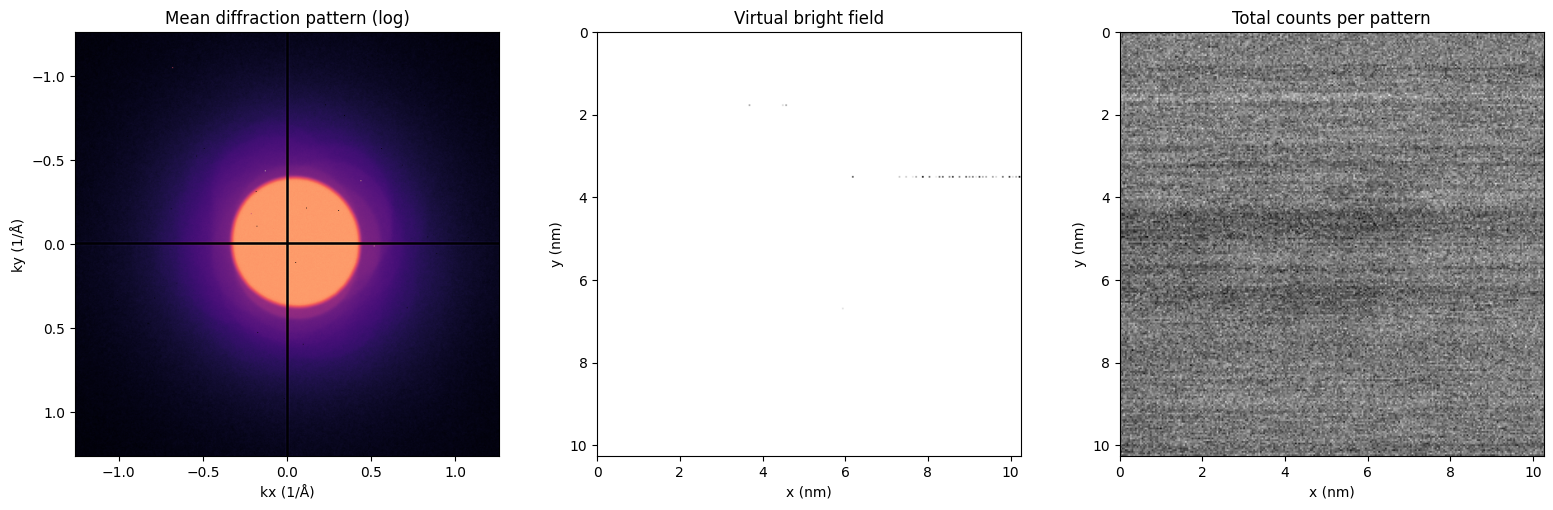

In [8]:
chk_store = zarr.ZipStore(OUTPUT_ZIP, mode="r")
g = zarr.open_group(chk_store, mode="r")
print(g.tree())
print("data:", g["data"].shape, g["data"].dtype, "chunks", g["data"].chunks, "|", g["data"].compressor)
print("meta:", json.dumps(g["meta"][0], indent=2))

rng = np.random.default_rng(0)
ok = True
with h5py.File(INPUT_H5, "r") as f:
    src = f[DATASET_PATH]
    for _ in range(20):
        r, c = int(rng.integers(Ry)), int(rng.integers(Rx))
        orig = np.rint(read_block(src, r, r + 1, c, c + 1)[0, 0])
        ok &= np.array_equal(orig, g["data"][r, c])
chk_store.close()
print("\n20 random patterns identical to the HDF5 source"
      + (f" (after {BIN}x{BIN} binning)" if BIN > 1 else "") + ":", ok)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(np.log10(mean_dp + 1e-3), extent=ext, cmap="magma")
ax[0].set_title("Mean diffraction pattern (log)"); ax[0].set_xlabel("kx (1/Å)"); ax[0].set_ylabel("ky (1/Å)")
ext_r = [0, Rx * meta["scan_step"][1] / 10, Ry * meta["scan_step"][0] / 10, 0]
ax[1].imshow(vbf, extent=ext_r, cmap="gray"); ax[1].set_title("Virtual bright field")
ax[2].imshow(total, extent=ext_r, cmap="gray"); ax[2].set_title("Total counts per pattern")
for a in ax[1:]:
    a.set_xlabel("x (nm)"); a.set_ylabel("y (nm)")
plt.tight_layout(); plt.show()

## Step 6 — Compare with a reference dataset ✏️

Checks your converted file against a known-good file (e.g. another dataset from the same project), item by
item. This step works on its own: after a kernel restart, run the import cell and Step 1, then this step.

Each row is marked:

* **✓ same**
* **~ differs (expected)** – things that naturally differ between datasets (scan size, detector size,
  chunk size, the actual settings values, count levels)
* **✗ DIFFERENT** – a format detail that should match the reference; look at these

The last rows check that each file is consistent with itself (wavelength vs. voltage, and the bright-field
disk size vs. the convergence angle and detector calibration).

In [9]:
REFERENCE_ZIP = "/dls/science/groups/e02/Joshua/End_to_End_data/Data/210.zip"   # known-good file
NEW_ZIP = OUTPUT_ZIP                                                             # file to check

In [10]:
import zipfile

CONTROL_FILES = (".zgroup", ".zarray", ".zattrs")


def describe_zip(path):
    # Collect zip layout, Zarr settings, the metadata record and a small data sample
    with zipfile.ZipFile(path) as z:
        infos = z.infolist()
        names = [i.filename for i in infos]
        groups = [n for n in names if n.endswith(".zgroup")]
        prefix = min(groups, key=len)[:-len(".zgroup")] if groups else ""
        control = {n[len(prefix):]: json.loads(z.read(n)) for n in names
                   if n.startswith(prefix) and n.split("/")[-1] in CONTROL_FILES}
    d = {"prefix": prefix or "(none)",
         "stored": all(i.compress_type == zipfile.ZIP_STORED for i in infos),
         "control": control, "meta": None, "data": None}
    store = zarr.ZipStore(path, mode="r")
    try:
        g = zarr.open_group(store, mode="r", path=prefix.rstrip("/"))
        if "meta" in g:
            d["meta"] = g["meta"][0]
        if "data" in g:
            a = g["data"]
            c0, c1 = a.chunks[0], a.chunks[1]
            s = max(1, c0 // 8)
            samp = np.asarray(a[0:c0:s, 0:c1:s]).astype(np.int64)  # sample from the first chunk only
            per = samp.reshape(-1, *samp.shape[2:])
            d["data"] = {"shape": a.shape, "dtype": str(a.dtype), "chunks": a.chunks,
                         "min": int(per.min()), "max": int(per.max()),
                         "counts": float(per.sum(axis=(1, 2)).mean()),
                         "zeros": float((per == 0).mean()), "mean_dp": per.mean(axis=0)}
    finally:
        store.close()
    return d


def self_checks(d):
    # Consistency of a file with itself: wavelength vs voltage, disk size vs alpha + calibration
    m, a = d["meta"], d["data"]
    out = {}
    try:
        h, m0, e, c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0
        V = m["E_ev"]
        lam = h / np.sqrt(2 * m0 * e * V * (1 + e * V / (2 * m0 * c**2))) * 1e10
        out["wavelength"] = (f"{m['wavelength']:.6f} vs {lam:.6f} Å",
                             abs(m["wavelength"] - lam) / lam < 1e-4)
    except Exception as e:
        out["wavelength"] = (f"can't check ({e})", False)
    try:
        Q = a["shape"][2:]
        dk = np.sqrt((2 * m["k_max"][0] / Q[0]) * (2 * m["k_max"][1] / Q[1]))
        expect = m["alpha_rad"] / m["wavelength"] / dk
        mdp = a["mean_dp"]
        meas = np.sqrt((mdp > 0.5 * mdp.max()).sum() / np.pi)
        out["disk"] = (f"{meas:.1f} measured / {expect:.1f} expected px", abs(meas - expect) < 0.1 * expect)
    except Exception as e:
        out["disk"] = (f"can't check ({e})", False)
    return out


def compare(ref_path, new_path):
    ref, new = describe_zip(ref_path), describe_zip(new_path)
    rows = []

    def add(item, r, n, kind="must"):
        if r == n:
            status = "✓ same"
        else:
            status = "~ differs (expected)" if kind == "info" else "✗ DIFFERENT"
        rows.append((item, r, n, status))

    add("zip: top-level folder", ref["prefix"], new["prefix"])
    add("zip: entries stored uncompressed", ref["stored"], new["stored"])
    add("Zarr control files", sorted(ref["control"]), sorted(new["control"]))
    add(".zgroup", ref["control"].get(".zgroup"), new["control"].get(".zgroup"))

    for arr in ("data", "meta"):
        rz, nz = ref["control"].get(f"{arr}/.zarray", {}), new["control"].get(f"{arr}/.zarray", {})
        for k in sorted(set(rz) | set(nz)):
            kind = "info" if (arr == "data" and k in ("shape", "chunks")) else "must"
            add(f"{arr}/.zarray: {k}", rz.get(k, "(missing)"), nz.get(k, "(missing)"), kind)
        if arr == "data" and rz and nz:
            add("data: number of dimensions", len(rz["shape"]), len(nz["shape"]))
            add("data: whole patterns in each chunk",
                rz["chunks"][2:] == rz["shape"][2:], nz["chunks"][2:] == nz["shape"][2:])

    rm, nm = ref["meta"] or {}, new["meta"] or {}
    add("meta: field names", sorted(rm), sorted(nm))
    shape_of = lambda v: (type(v).__name__, len(v)) if isinstance(v, (list, tuple)) else type(v).__name__
    for k in sorted(set(rm) | set(nm)):
        add(f"meta.{k}: type/length", shape_of(rm[k]) if k in rm else "(missing)",
            shape_of(nm[k]) if k in nm else "(missing)")
        add(f"meta.{k}: value", rm.get(k, "(missing)"), nm.get(k, "(missing)"), "info")

    if ref["data"] and new["data"]:
        rd, nd = ref["data"], new["data"]
        add("sample: value range", f"{rd['min']}..{rd['max']}", f"{nd['min']}..{nd['max']}", "info")
        add("sample: mean counts per pattern", round(rd["counts"], 1), round(nd["counts"], 1), "info")
        add("sample: fraction of zero pixels", round(rd["zeros"], 3), round(nd["zeros"], 3), "info")
        rc, nc = self_checks(ref), self_checks(new)
        for k, label in (("wavelength", "check: wavelength vs E_ev"),
                         ("disk", "check: BF disk vs alpha & k_max")):
            ok_r, ok_n = rc[k][1], nc[k][1]
            status = "✓ consistent" if ok_n else "✗ CHECK (your file)"
            if not ok_r:
                status += " / reference also fails"
            rows.append((label, rc[k][0], nc[k][0], status))

    def cell(v, w):
        s = v if isinstance(v, str) else json.dumps(v) if isinstance(v, (dict, list)) else str(v)
        return s if len(s) <= w else s[:w - 1] + "…"

    W = (36, 40, 40, 22)
    print(f"Reference: {ref_path}\nYours:     {new_path}\n")
    print("  ".join(h.ljust(w) for h, w in zip(("item", "reference", "yours", "result"), W)))
    print("-" * (sum(W) + 6))
    for row in rows:
        print("  ".join(cell(v, w).ljust(w) for v, w in zip(row, W)))

    bad = [r for r in rows if r[3].startswith("✗")]
    print()
    if bad:
        print(f"{len(bad)} item(s) need a look:")
        for r in bad:
            print(f"  - {r[0]}: reference {cell(r[1], 70)} | yours {cell(r[2], 70)}")
    else:
        print("Structure matches the reference: same layout, array settings and metadata fields. "
              "Only dataset-specific values differ.")
    return rows


rows = compare(REFERENCE_ZIP, NEW_ZIP)

Reference: /dls/science/groups/e02/Joshua/End_to_End_data/Data/210.zip
Yours:     /dls/science/groups/e02/Joshua/Python_code/End_to_End/test.zip

item                                  reference                                 yours                                     result                
------------------------------------------------------------------------------------------------------------------------------------------------
zip: top-level folder                 (none)                                    (none)                                    ✓ same                
zip: entries stored uncompressed      True                                      True                                      ✓ same                
Zarr control files                    [".zgroup", "data/.zarray", "meta/.zarr…  [".zgroup", "data/.zarray", "meta/.zarr…  ✓ same                
.zgroup                               {"zarr_format": 2}                        {"zarr_format": 2}                        ✓ same 